# Why Do Models Fail on Rare Diseases?
## Notebook 1 — Preprocessing (CCS label space, MIMIC-IV)
University of Cambridge — Pietro Liò Group | Timothée Roina, 2026

Pipeline (following MedCo exactly):
  ICD-10 Dx/Px → ICD-9 via CMS GEM files (self-contained)
  ICD-9 Dx     → CCS via PyHealth CrossMap
  NDC Rx       → ATC level-3 via PyHealth CrossMap

> **Notes added during the November 2026 review (code unchanged).**
> 1. *Targets.* Section 8 keeps **all** CCS codes of visit $k+1$ (codes already in the history are not removed), as in MedCo. Results are therefore for next-visit diagnosis prediction, not new-diagnosis prediction.
> 2. *Split.* The cell in Section 7 now reads `test_size=0.20` (an 80/10/10 split), but the saved outputs (70,114 / 15,024 / 15,025 patients) come from a 70/15/15 split. The artifacts on the cluster are the 70/15/15 ones; re-running this cell as written would change the split.
> 3. *Training k.* The comment says $k \in \{2,\dots,K-1\}$; the code uses `range(1, K)`, i.e. $k \in \{1,\dots,K-1\}$.
> 4. *GEM rule.* "First mapping wins" sends ICD-10 `I10` (essential hypertension) to ICD-9 401.0 (malignant) and hence to CCS 7.1.2.2 instead of 7.1.1 (see the printout in Section 3a and Notebook 4, Section 1b).
> 5. *Vocabulary.* No prevalence threshold is applied: 572 labels.

## 0. Installs

In [1]:
%pip install pyhealth pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and Paths

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import json
from pathlib import Path
from collections import Counter
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from pyhealth.medcode import CrossMap

ROOT      = Path('..')
DATA      = ROOT / 'data' / 'hosp'
MAPPINGS  = ROOT / 'data' / 'mappings'  # CMS GEM files (public domain)
PROCESSED = ROOT / 'processed'
FIGURES   = ROOT / 'figures'
RESULTS   = ROOT / 'results'

for d in [PROCESSED, FIGURES, RESULTS]:
    d.mkdir(parents=True, exist_ok=True)

print("Imports OK")
print(f"Data     : {DATA.resolve()}")
print(f"Mappings : {MAPPINGS.resolve()}")

Imports OK
Data     : /Users/r/Documents/cambridge_project/data/hosp
Mappings : /Users/r/Documents/cambridge_project/data/mappings


## 2. Load Raw Tables (only columns we use)

In [3]:
admissions = pd.read_csv(DATA / 'admissions.csv.gz',
    usecols=['subject_id', 'hadm_id', 'admittime'])

diagnoses = pd.read_csv(DATA / 'diagnoses_icd.csv.gz',
    usecols=['subject_id', 'hadm_id', 'icd_code', 'icd_version'])

patients = pd.read_csv(DATA / 'patients.csv.gz',
    usecols=['subject_id', 'anchor_age'])

procedures = pd.read_csv(DATA / 'procedures_icd.csv.gz',
    usecols=['subject_id', 'hadm_id', 'icd_code', 'icd_version'])

prescriptions = pd.read_csv(DATA / 'prescriptions.csv.gz',
    usecols=['subject_id', 'hadm_id', 'ndc'])

print(f"admissions    : {admissions.shape[0]:>10,} rows")
print(f"diagnoses     : {diagnoses.shape[0]:>10,} rows")
print(f"patients      : {patients.shape[0]:>10,} rows")
print(f"procedures    : {procedures.shape[0]:>10,} rows")
print(f"prescriptions : {prescriptions.shape[0]:>10,} rows")

admissions    :    546,028 rows
diagnoses     :  6,364,488 rows
patients      :    364,627 rows
procedures    :    859,655 rows
prescriptions : 20,292,611 rows


In [4]:
print("ICD version distribution — diagnoses:")
print(diagnoses['icd_version'].value_counts())
print("\nICD version distribution — procedures:")
print(procedures['icd_version'].value_counts())

ICD version distribution — diagnoses:
10    3455747
9     2908741
Name: icd_version, dtype: int64

ICD version distribution — procedures:
9     469209
10    390446
Name: icd_version, dtype: int64


## 3. Code Mappers

### 3a. ICD-10 → ICD-9 (CMS GEM files, public domain)
Source: https://www.nber.org/research/data/icd-9-cm-and-icd-10-cm-and-icd-10-pcs-crosswalk-or-general-equivalence-mappings
Files must be in data/mappings/ — copy from MedCo/saved_files/icd_maping/

In [5]:
class ICD10toICD9:
    """Maps ICD-10-CM/PCS codes to ICD-9 via CMS GEM file."""
    def __init__(self, gem_path: Path):
        df = pd.read_csv(gem_path, sep=r'\s+', header=None,
                         names=['icd10', 'icd9', 'flag'], dtype=str)
        self.mapping = {}
        for icd10, icd9 in zip(df['icd10'], df['icd9']):
            icd10, icd9 = str(icd10).strip(), str(icd9).strip()
            if icd10 not in self.mapping:
                self.mapping[icd10] = icd9

    def map(self, code):
        if isinstance(code, str):
            return self.mapping.get(code, None)
        return [self.mapping.get(c, None) for c in code]

dx_mapper = ICD10toICD9(MAPPINGS / '2018_I10gem.txt')
px_mapper = ICD10toICD9(MAPPINGS / 'gem_pcsi9.txt')

print(f"Dx GEM: {len(dx_mapper.mapping):,} ICD-10 codes")
print(f"Px GEM: {len(px_mapper.mapping):,} ICD-10 codes")
print(f"E119 (T2 diabetes)  → ICD-9: {dx_mapper.map('E119')}")
print(f"I10  (Hypertension) → ICD-9: {dx_mapper.map('I10')}")

Dx GEM: 71,704 ICD-10 codes
Px GEM: 78,705 ICD-10 codes
E119 (T2 diabetes)  → ICD-9: 25000
I10  (Hypertension) → ICD-9: 4010


### 3b. ICD-9 → CCS (PyHealth)

In [6]:
import csv

CCS_FILE = Path('/Users/r/Documents/cambridge_project/data/mappings/'
                'Multi_Level_CCS_2015/ccs_multi_dx_tool_2015.csv')

ccs4_map = {}

with open(CCS_FILE, 'r') as f:
    reader = csv.reader(f)
    next(reader)  # skip header
    for row in reader:
        row = [field.strip().strip("'").strip() for field in row]
        icd9 = row[0]
        if not icd9:
            continue
        # CCS LVL 4 EXT = most granular level available
        # Indices: LVL1=1, LVL2=3, LVL3=5, LVL4=7
        ccs_ext = None
        for idx in [7, 5, 3, 1]:
            val = row[idx] if idx < len(row) else ''
            if val and val != ' ':
                ccs_ext = val
                break
        if ccs_ext:
            ccs4_map[icd9] = ccs_ext

print(f"ICD-9 codes mapped    : {len(ccs4_map):,}")
print(f"Unique CCS LVL 4 EXT  : {len(set(ccs4_map.values()))}")

class CSSMappingLvl4:
    def map(self, icd9_code):
        code = str(icd9_code).strip().replace('.', '')
        result = ccs4_map.get(code, None)
        if result is None:
            result = ccs4_map.get(code.zfill(5), None)
        return [result] if result else None

ccs_mapping = CSSMappingLvl4()

# Sanity checks
print(f"4280  (Heart failure) → {ccs_mapping.map('4280')}")
print(f"25000 (T2 diabetes)   → {ccs_mapping.map('25000')}")
print(f"4019  (Hypertension)  → {ccs_mapping.map('4019')}")
print(f"2720  (Hyperlipidemia)→ {ccs_mapping.map('2720')}")
print(f"5711  (Alcoholic cirr)→ {ccs_mapping.map('5711')}")

ICD-9 codes mapped    : 15,072
Unique CCS LVL 4 EXT  : 589
4280  (Heart failure) → ['7.2.11.1']
25000 (T2 diabetes)   → ['3.2']
4019  (Hypertension)  → ['7.1.1']
2720  (Hyperlipidemia)→ ['3.6']
5711  (Alcoholic cirr)→ ['5.11']


### 3c. NDC → ATC level-3 (PyHealth)

In [7]:
ndc_to_atc = CrossMap("NDC", "ATC")

test = ndc_to_atc.map("00527051210", target_kwargs={"level": 3})
print(f"NDC 00527051210 → ATC level-3: {test}")

NDC 00527051210 → ATC level-3: ['A11C']


## 4. Visit Complexity (Hypothesis B)
How many codes per visit after ATC mapping?

Computing ATC codes per visit (may take a few minutes)...
Mean Dx per visit       : 11.7
Mean Px per visit       : 1.6
Mean Rx (ATC) per visit : 18.1
Mean TOTAL per visit    : 31.3

→ A single rare Dx contributes 1/31 ≈ 0.032 of v_t under mean pooling
Computing ATC codes per visit (may take a few minutes)...

Mean Dx per visit         : 11.7
Mean Px per visit         : 1.6
Mean Rx (ATC) per visit   : 18.1
Mean TOTAL per visit      : 31.3

→ A single rare Dx contributes 1/31 ≈ 0.032 of v_t under mean pooling


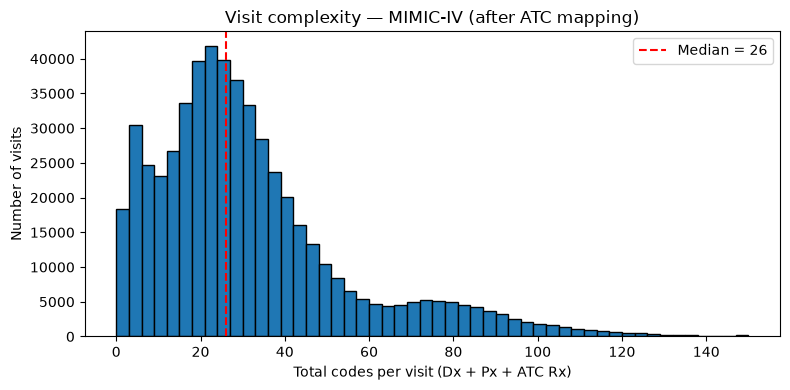

In [8]:
# ATC codes per visit (deduplicated — many NDC → same ATC)
def ndc_to_atc_list(ndc_series):
    atc_codes = set()
    for ndc in ndc_series:
        try:
            if pd.isna(ndc) or float(ndc) == 0:
                continue
            ndc_str = str(int(float(ndc))).zfill(11)
            mapped  = ndc_to_atc.map(ndc_str, target_kwargs={"level": 3})
            if mapped:
                atc_codes.update(mapped)
        except:
            pass
    return list(atc_codes)

print("Computing ATC codes per visit (may take a few minutes)...")
rx_atc_per_visit = (
    prescriptions.groupby('hadm_id')['ndc']
    .apply(ndc_to_atc_list)
)
rx_atc_counts = rx_atc_per_visit.apply(len)

dx_counts = diagnoses.groupby('hadm_id').size()
px_counts = procedures.groupby('hadm_id').size()

total = pd.concat([dx_counts, px_counts, rx_atc_counts], axis=1)
total.columns = ['dx', 'px', 'rx_atc']
total = total.fillna(0)
total['total'] = total.sum(axis=1)

print(f"Mean Dx per visit       : {total['dx'].mean():.1f}")
print(f"Mean Px per visit       : {total['px'].mean():.1f}")
print(f"Mean Rx (ATC) per visit : {total['rx_atc'].mean():.1f}")
print(f"Mean TOTAL per visit    : {total['total'].mean():.1f}")
print(f"\n→ A single rare Dx contributes "
      f"1/{total['total'].mean():.0f} ≈ "
      f"{1/total['total'].mean():.3f} of v_t under mean pooling")

print("Computing ATC codes per visit (may take a few minutes)...")
rx_atc_per_visit = (
    prescriptions.groupby('hadm_id')['ndc']
    .apply(ndc_to_atc_list)
)
rx_atc_counts = rx_atc_per_visit.apply(len)

dx_counts = diagnoses.groupby('hadm_id').size()
px_counts = procedures.groupby('hadm_id').size()

total = pd.concat([dx_counts, px_counts, rx_atc_counts], axis=1)
total.columns = ['dx', 'px', 'rx_atc']
total = total.fillna(0)
total['total'] = total.sum(axis=1)

print(f"\nMean Dx per visit         : {total['dx'].mean():.1f}")
print(f"Mean Px per visit         : {total['px'].mean():.1f}")
print(f"Mean Rx (ATC) per visit   : {total['rx_atc'].mean():.1f}")
print(f"Mean TOTAL per visit      : {total['total'].mean():.1f}")
print(f"\n→ A single rare Dx contributes "
      f"1/{total['total'].mean():.0f} ≈ "
      f"{1/total['total'].mean():.3f} of v_t under mean pooling")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(total['total'].clip(upper=150), bins=50, edgecolor='black')
ax.axvline(total['total'].median(), color='red', linestyle='--',
           label=f"Median = {total['total'].median():.0f}")
ax.set_xlabel('Total codes per visit (Dx + Px + ATC Rx)')
ax.set_ylabel('Number of visits')
ax.set_title('Visit complexity — MIMIC-IV (after ATC mapping)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / 'visit_complexity.png', dpi=150)
plt.show()

## 5. Build Patient Visits

In [9]:
# Adult cohort, including patients with no admission record
adult_ids = patients.loc[
    patients["anchor_age"] >= 18, "subject_id"
].unique()

admissions["admittime"] = pd.to_datetime(admissions["admittime"])
admissions = (
    admissions[admissions["subject_id"].isin(adult_ids)]
    .sort_values(["subject_id", "admittime"])
)

# Reindex against every adult patient so zero-admission patients are visible
admission_counts = (
    admissions.groupby("subject_id")["hadm_id"]
    .nunique()
    .reindex(adult_ids, fill_value=0)
)

count_table = (
    admission_counts.value_counts()
    .sort_index()
    .rename_axis("n_admissions")
    .reset_index(name="n_patients")
)

print(f"Adult patients                 : {len(adult_ids):,}")
print(f"Adult admissions               : {len(admissions):,}")
print(f"Patients with 0 admissions     : {(admission_counts == 0).sum():,}")
print(f"Patients with 1 admission      : {(admission_counts == 1).sum():,}")
print(f"Patients with 2 admissions     : {(admission_counts == 2).sum():,}")
print(f"Patients with >= 3 admissions  : {(admission_counts >= 3).sum():,}")

display(count_table)

# Eligible for next-visit prediction: at least one history visit + one future visit
eligible_ids = admission_counts[admission_counts >= 2].index

patient_visits = (
    admissions[admissions["subject_id"].isin(eligible_ids)]
    .groupby("subject_id")["hadm_id"]
    .apply(list)
    .to_dict()
)

print(f"Eligible next-visit patients   : {len(patient_visits):,}")

Adult patients                 : 364,627
Adult admissions               : 546,028
Patients with 0 admissions     : 141,175
Patients with 1 admission      : 123,289
Patients with 2 admissions     : 44,123
Patients with >= 3 admissions  : 56,040


,n_admissions,n_patients
0,0,141175
1,1,123289
2,2,44123
3,3,20108
4,4,11172
...,...,...
93,138,1
94,142,1
95,163,1
96,185,1


Eligible next-visit patients   : 100,163


## 6. Build Code Lookup Tables per Visit

In [10]:
# ============================================================
# Cell 6 — Build Code Lookup Tables + Patient Sequences
# ============================================================

# --- CCS procedure mapping (optional) ---
try:
    ccs_px_mapping = CrossMap("ICD9PROC", "CCSPROC")
    test = ccs_px_mapping.map("5491")
    print(f"ICD9PROC→CCSPROC works: 5491 → {test}")
except Exception as e:
    print(f"CCSPROC not available: {e} — using raw ICD-9 Px")
    ccs_px_mapping = None

# --- Helper: ICD-9 code lookup (converts ICD-10 via GEM) ---
def get_icd9_codes(hadm_id, lookup, mapper):
    """Return ICD-9 codes for a visit (convert ICD-10 via GEM)."""
    rows = lookup.get(hadm_id, [])
    result = []
    for code, version in rows:
        code = str(code).strip()
        if version == 9:
            result.append(code)
        else:
            icd9 = mapper.map(code)
            if icd9:
                result.append(icd9)
    return result

# --- Lookup dicts ---
diagnoses_by_hadm = (
    diagnoses.groupby('hadm_id')
    .apply(lambda df: list(zip(df['icd_code'], df['icd_version'])))
    .to_dict()
)
procedures_by_hadm = (
    procedures.groupby('hadm_id')
    .apply(lambda df: list(zip(df['icd_code'], df['icd_version'])))
    .to_dict()
)
rx_by_hadm = rx_atc_per_visit.to_dict()

print(f"Visits with Dx : {len(diagnoses_by_hadm):,}")
print(f"Visits with Px : {len(procedures_by_hadm):,}")
print(f"Visits with Rx : {len(rx_by_hadm):,}")

# --- Build and save patient sequences ---
# Dx: ICD-9 → CCS (same space as labels)
# Px: ICD-9 → CCS procedure (via CCSPROC if available, else raw ICD-9)
# Rx: ATC level-3 (already mapped in rx_by_hadm)
def build_patient_sequences(patient_visits, diagnoses_by_hadm,
                             procedures_by_hadm, rx_by_hadm,
                             dx_mapper, px_mapper,
                             ccs_mapping, ccs_px_mapping=None):
    sequences = {}
    for pid, hadm_list in tqdm(patient_visits.items(),
                                desc="Building sequences"):
        seq = []
        for hadm in hadm_list:

            # Dx: ICD-10 → ICD-9 → CCS
            dx_icd9 = get_icd9_codes(hadm, diagnoses_by_hadm, dx_mapper)
            dx_ccs = set()
            for code in dx_icd9:
                mapped = ccs_mapping.map(code)
                if mapped:
                    dx_ccs.update(mapped)
            dx = list(dx_ccs)

            # Px: ICD-10-PCS → ICD-9 → CCS procedure (if available)
            px_icd9 = get_icd9_codes(hadm, procedures_by_hadm, px_mapper)
            if ccs_px_mapping is not None:
                px_ccs = set()
                for code in px_icd9:
                    mapped = ccs_px_mapping.map(code)
                    if mapped:
                        px_ccs.update(mapped)
                px = list(px_ccs)
            else:
                px = px_icd9  # fallback: raw ICD-9 Px

            # Rx: ATC level-3 (already mapped)
            rx = rx_by_hadm.get(hadm, [])

            seq.append((hadm, dx, px, rx))
        sequences[pid] = seq
    return sequences

patient_sequences = build_patient_sequences(
    patient_visits, diagnoses_by_hadm, procedures_by_hadm,
    rx_by_hadm, dx_mapper, px_mapper,
    ccs_mapping, ccs_px_mapping
)

with open(PROCESSED / 'patient_sequences.pkl', 'wb') as f:
    pickle.dump(patient_sequences, f)
print(f"Saved patient_sequences.pkl — {len(patient_sequences):,} patients, full histories")

ICD9PROC→CCSPROC works: 5491 → ['88']
Visits with Dx : 545,497
Visits with Px : 287,504
Visits with Rx : 463,328


Building sequences: 100%|██████████| 100163/100163 [00:04<00:00, 20334.89it/s]


Saved patient_sequences.pkl — 100,163 patients, full histories


## 7. Build Samples
Input: (Dx ICD-9, Px ICD-9, Rx ATC) at visits 1..k
Target: NEW CCS diagnosis codes at visit k+1

In [ ]:
## 7. Train / Val / Test Split (70/15/15, patient-level)
# Moved BEFORE sampling: k-selection now differs by split, so patients
# must be assigned to a split before their samples are built.
unique_patients = list(patient_visits.keys())

train_pts, temp_pts = train_test_split(unique_patients,
                                        test_size=0.20, random_state=42)
val_pts,   test_pts = train_test_split(temp_pts,
                                        test_size=0.50, random_state=42)

train_set = set(train_pts)
val_set   = set(val_pts)
test_set  = set(test_pts)

print(f"Train patients : {len(train_pts):,}")
print(f"Val patients   : {len(val_pts):,}")
print(f"Test patients  : {len(test_pts):,}")

Train patients : 70,114
Val patients   : 15,024
Test patients  : 15,025


## 8. Train / Val / Test Split (70/15/15, patient-level)

In [ ]:
## 8. Build Samples — k protocol enforced per methodology
# Same accumulation logic as the original build_samples (history_ccs grows
# cumulatively per visit), but:
#   - k range restricted per split (train: {2,...,K-1}; val/test: {floor(K/2)})
#   - full visit list up to k is preserved per sample (needed for the
#     Transformer's actual sequence input, not just the label-history check)

def build_samples(patient_visits, diagnoses_by_hadm, procedures_by_hadm,
                   rx_by_hadm, dx_mapper, px_mapper, ccs_mapping,
                   split_set, split_name):
    samples = []
    dropped_no_valid_k = 0

    for pid, hadm_list in tqdm(patient_visits.items(), desc=f"Building {split_name} samples"):
        if pid not in split_set:
            continue

        K = len(hadm_list)
        if split_name == 'train':
            ks = list(range(1, K))          # every admissible k, {1,...,K-1} 
        else:
            k_mid = K // 2
            ks = [k_mid] if k_mid >= 1 else []

        if not ks:
            dropped_no_valid_k += 1
            continue

        # Precompute cumulative CCS history at every visit index once per patient
        history_ccs_by_k = []   # history_ccs_by_k[k] = CCS history AFTER visits 0..k
        running = set()
        for hadm in hadm_list:
            dx = get_icd9_codes(hadm, diagnoses_by_hadm, dx_mapper)
            for code in dx:
                mapped = ccs_mapping.map(code)
                if mapped:
                    running.update(mapped)
            history_ccs_by_k.append(set(running))  # snapshot

        for k in ks:
            cur_hadm = hadm_list[k - 1]   # last visit included in history (0-indexed k-1)
            nxt_hadm = hadm_list[k]       # visit k+1 (0-indexed k)

            history_ccs = history_ccs_by_k[k - 1]

            dx_next = get_icd9_codes(nxt_hadm, diagnoses_by_hadm, dx_mapper)
            target_ccs = set()
            for code in dx_next:
                mapped = ccs_mapping.map(code)
                if mapped:
                    target_ccs.update(mapped)
                    
            # we do not remove any codes already present in history, to compare with baseline models in the literature
            
            if not target_ccs:
                continue  # skip samples with no valid target CCS codes

            samples.append({
                "patient_id": pid,
                "hadm_id":    nxt_hadm,
                "k":          k,
                "history_hadm_ids": hadm_list[:k],  # visits 1..k, for sequence lookup
                "label":      list(target_ccs),
            })

    print(f"[{split_name}] {len(samples):,} samples "
          f"({dropped_no_valid_k:,} patients dropped: no valid k)")
    return samples

train_samples = build_samples(patient_visits, diagnoses_by_hadm, procedures_by_hadm,
                               rx_by_hadm, dx_mapper, px_mapper, ccs_mapping,
                               train_set, 'train')
val_samples   = build_samples(patient_visits, diagnoses_by_hadm, procedures_by_hadm,
                               rx_by_hadm, dx_mapper, px_mapper, ccs_mapping,
                               val_set, 'val')
test_samples  = build_samples(patient_visits, diagnoses_by_hadm, procedures_by_hadm,
                               rx_by_hadm, dx_mapper, px_mapper, ccs_mapping,
                               test_set, 'test')

print(f"\nTotal train samples : {len(train_samples):,}")
print(f"Total val samples   : {len(val_samples):,}")
print(f"Total test samples  : {len(test_samples):,}")

Building train samples: 100%|██████████| 100163/100163 [00:03<00:00, 25357.65it/s]


[train] 225,024 samples (0 patients dropped: no valid k)


Building val samples: 100%|██████████| 100163/100163 [00:00<00:00, 133166.20it/s]


[val] 15,004 samples (0 patients dropped: no valid k)


Building test samples: 100%|██████████| 100163/100163 [00:00<00:00, 161507.42it/s]

[test] 15,010 samples (0 patients dropped: no valid k)

Total train samples : 225,024
Total val samples   : 15,004
Total test samples  : 15,010


In [13]:
# How many diagnoses are lost at each mapping step?
total_dx_rows = len(diagnoses)
icd9_rows     = (diagnoses['icd_version'] == 9).sum()
icd10_rows    = (diagnoses['icd_version'] == 10).sum()

# ICD-10 → ICD-9 coverage
icd10_codes  = diagnoses[diagnoses['icd_version'] == 10]['icd_code']
mapped_count = icd10_codes.apply(lambda c: dx_mapper.map(str(c).strip()) is not None).sum()

print(f"Total diagnosis rows      : {total_dx_rows:,}")
print(f"ICD-9 rows (no mapping)   : {icd9_rows:,} ({100*icd9_rows/total_dx_rows:.1f}%)")
print(f"ICD-10 rows               : {icd10_rows:,} ({100*icd10_rows/total_dx_rows:.1f}%)")
print(f"ICD-10 successfully → ICD-9: {mapped_count:,} ({100*mapped_count/icd10_rows:.1f}%)")

# ICD-9 → CCS coverage
sample_icd9 = diagnoses[diagnoses['icd_version'] == 9]['icd_code'].unique()[:100]
ccs_mapped  = sum(1 for c in sample_icd9
                  if ccs_mapping.map(str(c).strip()))
print(f"\nICD-9 → CCS sample coverage: {ccs_mapped}/100")

# Coverage check
all_ccs = set()
for s in train_samples + val_samples + test_samples:
    all_ccs.update(s['label'])

print(f"Unique CCS codes we get: {len(all_ccs)}")
print(f"Expected (MedCo):        562")
print(f"Gap:                     {562 - len(all_ccs)}")

Total diagnosis rows      : 6,364,488
ICD-9 rows (no mapping)   : 2,908,741 (45.7%)
ICD-10 rows               : 3,455,747 (54.3%)
ICD-10 successfully → ICD-9: 3,369,169 (97.5%)

ICD-9 → CCS sample coverage: 100/100
Unique CCS codes we get: 573
Expected (MedCo):        562
Gap:                     -11


## 9. CCS Vocabulary from Training Set
Filter: prevalence >= 0.1% of training patients

In [14]:
# Count each CCS target label at most once per training patient.
patient_labels = {}

for s in train_samples:
    pid = s["patient_id"]
    patient_labels.setdefault(pid, set()).update(s["label"])

train_code_counts = Counter()

for labels in patient_labels.values():
    train_code_counts.update(labels)

# No prevalence threshold: retain every CCS target label seen in training.
vocab = sorted(train_code_counts.keys())

N = len(vocab)
code2idx = {c: i for i, c in enumerate(vocab)}

freqs = np.array([train_code_counts[c] for c in vocab])
q25 = np.percentile(freqs, 25)
q75 = np.percentile(freqs, 75)

rare_idx = [
    i for i, c in enumerate(vocab)
    if train_code_counts[c] <= q25
]
medium_idx = [
    i for i, c in enumerate(vocab)
    if q25 < train_code_counts[c] <= q75
]
common_idx = [
    i for i, c in enumerate(vocab)
    if train_code_counts[c] > q75
]

print(f"CCS vocabulary N  : {N} codes")
print(f"Rare   (≤ {q25:.0f}) : {len(rare_idx)} codes")
print(f"Medium            : {len(medium_idx)} codes")
print(f"Common (> {q75:.0f}) : {len(common_idx)} codes")

CCS vocabulary N  : 572 codes
Rare   (≤ 166) : 143 codes
Medium            : 286 codes
Common (> 2688) : 143 codes


## 10. Label Frequency Distribution

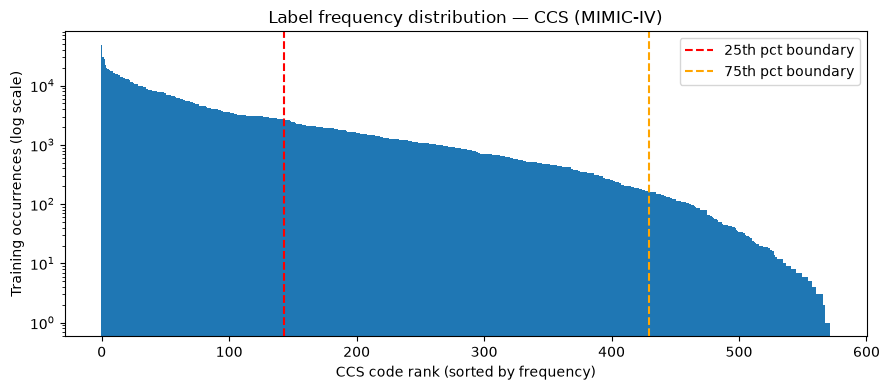

Top 20 codes account for 28.5% of all occurrences
Max/Min frequency ratio: 47,949 / 1 = 47,949x


In [15]:
freqs_sorted = sorted(freqs, reverse=True)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(freqs_sorted)), freqs_sorted, width=1.0)
ax.set_yscale('log')
ax.axvline(len(rare_idx), color='red', linestyle='--',
           label='25th pct boundary')
ax.axvline(len(rare_idx) + len(medium_idx), color='orange',
           linestyle='--', label='75th pct boundary')
ax.set_xlabel('CCS code rank (sorted by frequency)')
ax.set_ylabel('Training occurrences (log scale)')
ax.set_title('Label frequency distribution — CCS (MIMIC-IV)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / 'label_frequency_ccs.png', dpi=150)
plt.show()

top20_share = sum(freqs_sorted[:20]) / sum(freqs_sorted) * 100
print(f"Top 20 codes account for {top20_share:.1f}% of all occurrences")
print(f"Max/Min frequency ratio: {max(freqs_sorted):,} / {min(freqs_sorted)} = "
      f"{max(freqs_sorted)//min(freqs_sorted):,}x")

## 11. Filter to Vocabulary and Save

In [16]:
def filter_to_vocab(samples, code2idx):
    filtered = []
    for s in samples:
        labels = [c for c in s["label"] if c in code2idx]
        filtered.append({**s, "label": labels})
    return filtered

train_f = filter_to_vocab(train_samples, code2idx)
val_f   = filter_to_vocab(val_samples, code2idx)
test_f  = filter_to_vocab(test_samples, code2idx)

new_dx_counts = [len(s['label']) for s in train_f]
m_median = int(np.median(new_dx_counts))
m_90     = int(np.percentile(new_dx_counts, 90))

meta = {
    "vocab": vocab, "code2idx": code2idx, "N": N,
    "q25": float(q25), "q75": float(q75),
    "rare_idx": rare_idx, "medium_idx": medium_idx,
    "common_idx": common_idx,
    "m_median": m_median, "m_90": m_90,
    "n_train_pts": len(train_pts),
    "n_val_pts":   len(val_pts),
    "n_test_pts":  len(test_pts),
    "label_space": "CCS",
}

with open(PROCESSED / 'meta_ccs.json', 'w') as f:
    json.dump(meta, f, indent=2)
with open(PROCESSED / 'train_samples.pkl', 'wb') as f:
    pickle.dump(train_f, f)
with open(PROCESSED / 'val_samples.pkl', 'wb') as f:
    pickle.dump(val_f, f)
with open(PROCESSED / 'test_samples.pkl', 'wb') as f:
    pickle.dump(test_f, f)

print(f"Train : {len(train_f):,} samples")
print(f"Val   : {len(val_f):,} samples")
print(f"Test  : {len(test_f):,} samples")
print(f"Acc@m : Acc@{m_median} (median), Acc@{m_90} (90th pct)")
print("Saved to processed/")

Train : 225,024 samples
Val   : 15,004 samples
Test  : 15,010 samples
Acc@m : Acc@11 (median), Acc@20 (90th pct)
Saved to processed/


## 12. Summary

In [17]:
print("=" * 55)
print("PREPROCESSING SUMMARY")
print("=" * 55)
print(f"Label space   : CCS ({N} codes)")
print(f"Patients      : {len(unique_patients):,}")
print(f"Train samples : {len(train_f):,}")
print(f"Val samples   : {len(val_f):,}")
print(f"Test samples  : {len(test_f):,}")
print(f"Rare codes    : {len(rare_idx)} (≤ {q25:.0f} train occ.)")
print(f"Common codes  : {len(common_idx)} (> {q75:.0f} train occ.)")
print(f"Acc@m         : Acc@{m_median}, Acc@{m_90}")
print(f"Mapping       : ICD-10→ICD-9 (CMS GEM) → CCS | NDC→ATC level-3")
print("=" * 55)
print("→ Ready for Notebook 2: Backbone Transformer")

PREPROCESSING SUMMARY
Label space   : CCS (572 codes)
Patients      : 100,163
Train samples : 225,024
Val samples   : 15,004
Test samples  : 15,010
Rare codes    : 143 (≤ 166 train occ.)
Common codes  : 143 (> 2688 train occ.)
Acc@m         : Acc@11, Acc@20
Mapping       : ICD-10→ICD-9 (CMS GEM) → CCS | NDC→ATC level-3
→ Ready for Notebook 2: Backbone Transformer
